# Week 2 Step 6: Churn prediction

I am predicting `churned` from `customer_features.csv`. About 25% of customers churned, so a model that always says "stays" would look 75% accurate and still be useless. I am leading with recall, F1, and ROC-AUC, not accuracy.

I split train/test **before** any encoding or scaling. I drop `customer_id`, `registration_date`, `churn_date`, and `churn_reason` (those last two would leak the label). I also drop `city` because 89 cities would blow up one-hot encoding and I already have `country`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "processed").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

RANDOM_STATE = 42
df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "customer_features.csv")
print("rows:", len(df))
print("churn rate:", round(df["churned"].mean() * 100, 1), "%")
display(df["churned"].value_counts())

rows: 8000
churn rate: 24.9 %


churned
False    6009
True     1991
Name: count, dtype: int64

In [2]:
target = "churned"
drop_cols = [
    "customer_id",
    "registration_date",
    "churn_date",
    "churn_reason",
    "city",
    target,
]

y = df[target].astype(int)
X = df.drop(columns=drop_cols)

cat_cols = X.select_dtypes(include=["object", "bool"]).columns.tolist()
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("train:", len(X_train), "churn rate", round(y_train.mean() * 100, 1), "%")
print("test: ", len(X_test), "churn rate", round(y_test.mean() * 100, 1), "%")
print("numeric:", num_cols)
print("categorical:", cat_cols)

train: 6400 churn rate 24.9 %
test:  1600 churn rate 24.9 %
numeric: ['age', 'customer_tenure_days', 'avg_watch_time_per_session', 'monthly_watch_time_trend', 'days_since_last_activity', 'login_frequency', 'support_ticket_count', 'avg_customer_satisfaction', 'failed_payment_count', 'failed_payment_rate', 'customer_lifetime_value', 'plan_changes', 'engagement_score', 'feedback_count', 'avg_feedback_rating', 'avg_successful_payment_amount']
categorical: ['gender', 'country', 'acquisition_channel', 'customer_segment', 'preferred_language', 'current_plan_name']


I am using a `ColumnTransformer` inside a `Pipeline` so imputing, scaling, and one-hot encoding are fit on train folds only. For the trees I still use the same preprocessor so the comparison is fair. About 1 in 4 customers churned, so I am comparing each model with class-weight / `scale_pos_weight` against a version with no imbalance handling.

In [3]:
preprocess = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                ]
            ),
            num_cols,
        ),
        (
            "cat",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore")),
                ]
            ),
            cat_cols,
        ),
    ]
)

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos_weight = neg / pos
print("train not-churned / churned =", round(scale_pos_weight, 2))

candidates = {
    "logreg": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "logreg_balanced": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "random_forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "random_forest_balanced": RandomForestClassifier(
        n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "grad_boost": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "xgboost": XGBClassifier(
        n_estimators=200,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
    ),
    "xgboost_weighted": XGBClassifier(
        n_estimators=200,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
    ),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "roc_auc": "roc_auc",
    "recall": "recall",
    "precision": "precision",
    "f1": "f1",
}

cv_rows = []
for name, model in candidates.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_rows.append(
        {
            "model": name,
            "roc_auc": scores["test_roc_auc"].mean(),
            "recall": scores["test_recall"].mean(),
            "precision": scores["test_precision"].mean(),
            "f1": scores["test_f1"].mean(),
        }
    )
    print(name, {k: round(cv_rows[-1][k], 3) for k in ["roc_auc", "recall", "precision", "f1"]})

cv_table = pd.DataFrame(cv_rows).sort_values("f1", ascending=False)
display(cv_table.round(3))

train not-churned / churned = 3.02
logreg {'roc_auc': 0.699, 'recall': 0.163, 'precision': 0.607, 'f1': 0.256}
logreg_balanced {'roc_auc': 0.702, 'recall': 0.641, 'precision': 0.369, 'f1': 0.468}
random_forest {'roc_auc': 0.756, 'recall': 0.191, 'precision': 0.714, 'f1': 0.302}
random_forest_balanced {'roc_auc': 0.757, 'recall': 0.403, 'precision': 0.528, 'f1': 0.457}
grad_boost {'roc_auc': 0.773, 'recall': 0.262, 'precision': 0.685, 'f1': 0.379}
xgboost {'roc_auc': 0.752, 'recall': 0.352, 'precision': 0.553, 'f1': 0.43}
xgboost_weighted {'roc_auc': 0.752, 'recall': 0.428, 'precision': 0.501, 'f1': 0.461}


,model,roc_auc,recall,precision,f1
1,logreg_balanced,0.702,0.641,0.369,0.468
6,xgboost_weighted,0.752,0.428,0.501,0.461
3,random_forest_balanced,0.757,0.403,0.528,0.457
5,xgboost,0.752,0.352,0.553,0.430
4,grad_boost,0.773,0.262,0.685,0.379
2,random_forest,0.756,0.191,0.714,0.302
0,logreg,0.699,0.163,0.607,0.256


I pick the best **balanced / weighted** model on CV F1 (and I still look at recall and ROC-AUC). Then I fit it on the full training set, choose a probability threshold from the **training** precision-recall curve, and only then score the held-out test set.

model I am taking to the test set: logreg_balanced
threshold 0.50 vs chosen 0.46
train F1 at chosen threshold 0.494
train recall at chosen threshold 0.754


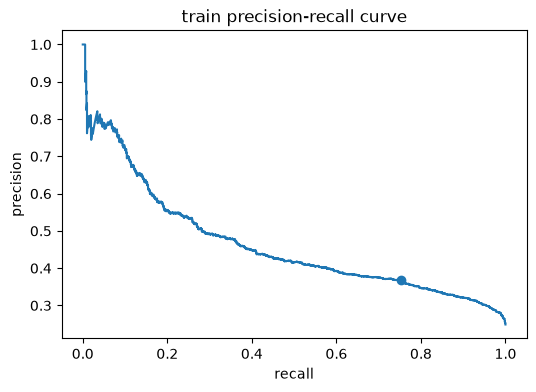

In [4]:
preferred = [
    "logreg_balanced",
    "random_forest_balanced",
    "grad_boost",
    "xgboost_weighted",
]
best_name = cv_table.loc[cv_table["model"].isin(preferred)].iloc[0]["model"]
print("model I am taking to the test set:", best_name)

final_pipe = Pipeline([("prep", preprocess), ("model", candidates[best_name])])
final_pipe.fit(X_train, y_train)

train_proba = final_pipe.predict_proba(X_train)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_train, train_proba)
f1s = 2 * precisions * recalls / (precisions + recalls + 1e-12)
best_i = int(np.nanargmax(f1s[:-1])) if len(thresholds) else 0
chosen_threshold = float(thresholds[best_i]) if len(thresholds) else 0.5

print("threshold 0.50 vs chosen", round(chosen_threshold, 3))
print("train F1 at chosen threshold", round(f1s[best_i], 3))
print("train recall at chosen threshold", round(recalls[best_i], 3))

plt.figure(figsize=(6, 4))
plt.plot(recalls, precisions)
plt.scatter(recalls[best_i], precisions[best_i])
plt.xlabel("recall")
plt.ylabel("precision")
plt.title("train precision-recall curve")
plt.show()

,threshold,accuracy,precision,recall,f1,roc_auc
0,0.50,0.623,0.357,0.641,0.458,0.696
1,0.46,0.581,0.337,0.709,0.457,0.696


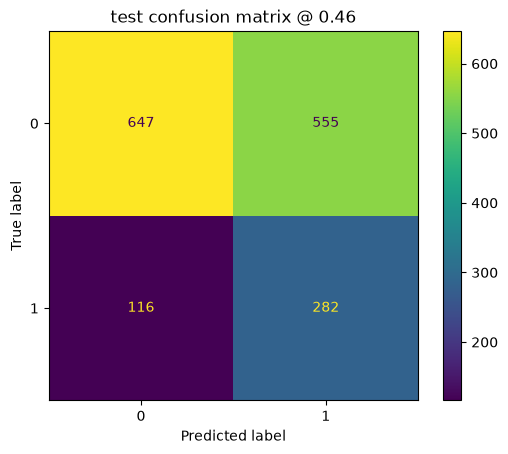

In [5]:
def metrics_at(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    return {
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, proba),
    }

test_proba = final_pipe.predict_proba(X_test)[:, 1]
test_table = pd.DataFrame(
    [
        metrics_at(y_test, test_proba, 0.5),
        metrics_at(y_test, test_proba, chosen_threshold),
    ]
)
display(test_table.round(3))

test_pred = (test_proba >= chosen_threshold).astype(int)
ConfusionMatrixDisplay.from_predictions(y_test, test_pred)
plt.title(f"test confusion matrix @ {chosen_threshold:.2f}")
plt.show()

## Step 7: Is this model too good?

The brief says churn is noisy on purpose. If ROC-AUC is something like 0.98, I am probably leaking. The feature I worry about most is `days_since_last_activity`: if I had computed it after cancel, the model could just learn "they already stopped watching so they churned". I computed it before each customer's cutoff, but I still want to see whether that one column is doing all the work.

importance type: abs(coef_)
test ROC-AUC: 0.696


,feature,importance,share
0,num__monthly_watch_time_trend,0.503518,0.062361
1,num__customer_lifetime_value,0.487402,0.060365
2,cat__country_Mexico,0.350986,0.043470
3,cat__country_South Korea,0.350215,0.043375
4,num__customer_tenure_days,0.316648,0.039217
5,cat__preferred_language_Unknown,0.294733,0.036503
6,num__login_frequency,0.280934,0.034794
7,num__avg_customer_satisfaction,0.273645,0.033891
8,num__failed_payment_rate,0.256127,0.031722
9,cat__preferred_language_Polish,0.239817,0.029702


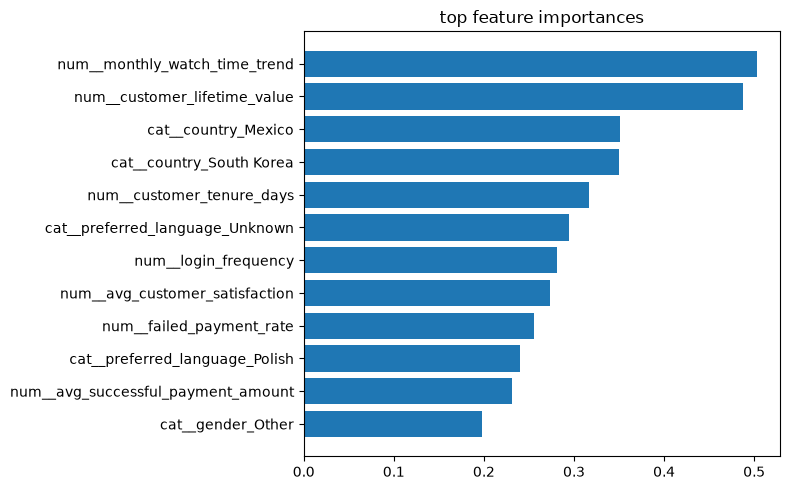

top feature share of total importance: 6.2 %


In [6]:
fitted_model = final_pipe.named_steps["model"]
feat_names = final_pipe.named_steps["prep"].get_feature_names_out()

if hasattr(fitted_model, "feature_importances_"):
    importance_values = fitted_model.feature_importances_
    importance_kind = "feature_importances_"
else:
    importance_values = np.abs(fitted_model.coef_[0])
    importance_kind = "abs(coef_)"

importance = (
    pd.DataFrame({"feature": feat_names, "importance": importance_values})
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)
importance["share"] = importance["importance"] / importance["importance"].sum()

print("importance type:", importance_kind)
print("test ROC-AUC:", round(roc_auc_score(y_test, test_proba), 3))
display(importance.head(15))

top = importance.head(12).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top["feature"], top["importance"])
plt.title("top feature importances")
plt.tight_layout()
plt.show()

print("top feature share of total importance:", round(importance.loc[0, "share"] * 100, 1), "%")

In [7]:
drop_check = "days_since_last_activity"
X_train_ablate = X_train.drop(columns=[drop_check])
X_test_ablate = X_test.drop(columns=[drop_check])
num_cols_ablate = [c for c in num_cols if c != drop_check]

preprocess_ablate = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="median")),
                    ("scaler", StandardScaler()),
                ]
            ),
            num_cols_ablate,
        ),
        (
            "cat",
            Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore")),
                ]
            ),
            cat_cols,
        ),
    ]
)

ablate_pipe = Pipeline([("prep", preprocess_ablate), ("model", candidates[best_name])])
ablate_cv = cross_validate(
    ablate_pipe, X_train_ablate, y_train, cv=cv, scoring=scoring, n_jobs=-1
)
full_row = cv_table.loc[cv_table["model"] == best_name].iloc[0]

print(f"CV with {drop_check}")
print("  roc_auc", round(full_row["roc_auc"], 3), "recall", round(full_row["recall"], 3), "f1", round(full_row["f1"], 3))
print(f"CV without {drop_check}")
print(
    "  roc_auc",
    round(ablate_cv["test_roc_auc"].mean(), 3),
    "recall",
    round(ablate_cv["test_recall"].mean(), 3),
    "f1",
    round(ablate_cv["test_f1"].mean(), 3),
)
print(
    "ROC-AUC drop:",
    round(full_row["roc_auc"] - ablate_cv["test_roc_auc"].mean(), 3),
)

CV with days_since_last_activity
  roc_auc 0.702 recall 0.641 f1 0.468
CV without days_since_last_activity
  roc_auc 0.702 recall 0.64 f1 0.468
ROC-AUC drop: 0.0


In [8]:
test_auc = roc_auc_score(y_test, test_proba)
auc_drop = full_row["roc_auc"] - ablate_cv["test_roc_auc"].mean()
top_name = importance.loc[0, "feature"]
top_share = importance.loc[0, "share"]

if test_auc >= 0.98:
    finding = (
        f"I do not trust this yet because test ROC-AUC is {test_auc:.3f}; "
        f"that is too close to perfect for a noisy churn label, so I would rebuild the cutoff in Step 2."
    )
elif auc_drop >= 0.10:
    finding = (
        f"I do not trust this yet because dropping {drop_check} cut CV ROC-AUC by {auc_drop:.3f}; "
        f"the model is leaning too hard on recency, so I would go back to Step 2."
    )
else:
    finding = (
        f"I trust these results enough to keep going: test ROC-AUC is {test_auc:.3f} (not near-perfect), "
        f"the top encoded feature is {top_name} at {top_share:.0%} of importance, "
        f"and dropping {drop_check} only moved CV ROC-AUC by {auc_drop:.3f}."
    )

print(finding)

I trust these results enough to keep going: test ROC-AUC is 0.696 (not near-perfect), the top encoded feature is num__monthly_watch_time_trend at 6% of importance, and dropping days_since_last_activity only moved CV ROC-AUC by 0.000.


## Why this model and this threshold

If I send a retention offer to someone who was never going to leave, that is a false positive: I spend a discount I did not need to spend. If I miss someone who then cancels, that is a false negative: I lose the subscriber, which this project treats as more expensive than the discount. So I care more about **recall** (catching real churners) than about squeezing precision, as long as precision does not collapse and waste the whole retention budget.

That is why I compared unweighted vs weighted models, picked the stronger F1/recall candidate from cross-validation, and moved the threshold using the training precision-recall curve instead of blindly using 0.5. Accuracy is in the table only as a sanity check. I would not use it to choose the model.